In [1]:
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [3]:
data=pd.read_csv("bank (1).csv")
data

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [4]:
x=data[['age', 'balance', 'duration']]
x

,age,balance,duration
0,59,2343,1042
1,56,45,1467
2,41,1270,1389
3,55,2476,579
4,54,184,673
...,...,...,...
11157,33,1,257
11158,39,733,83
11159,32,29,156
11160,43,0,9


In [13]:
y = data[['deposit']]
y

,deposit
0,yes
1,yes
2,yes
3,yes
4,yes
...,...
11157,no
11158,no
11159,no
11160,no


In [18]:
data = data.dropna()

In [20]:
le = LabelEncoder()
y = le.fit_transform(data['deposit'])

In [24]:
y

array([1, 1, 1, ..., 0, 0, 0])

In [30]:
model = GaussianNB()
model.fit(x, y)

GaussianNB()

In [31]:
y_pred = model.predict(x)

In [33]:
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred)
recall = recall_score(y, y_pred)
f1 = f1_score(y, y_pred)
cm = confusion_matrix(y, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print("Confusion Matrix:\n", cm)

Accuracy: 0.7033
Precision: 0.8042
Recall: 0.4940
F1 Score: 0.6121
Confusion Matrix:
 [[5237  636]
 [2676 2613]]


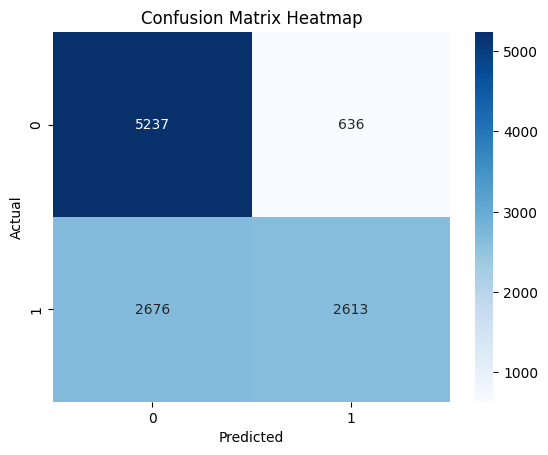

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(cm, annot=True,cmap='Blues',fmt='d')
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()